# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Fayyadh Tajuzzaman
- **Email:** fayyadhtz@gmail.com
- **ID Dicoding:** fyydhtz

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh kondisi cuaca (weathersit) terhadap rata-rata jumlah penyewaan sepeda harian (cnt) selama tahun 2011-2012, dan kondisi cuaca mana yang paling menurunkan penyewaan?
- **Pertanyaan 2:** Pada jam berapa puncak penyewaan sepeda terjadi pada hari kerja dibandingkan akhir pekan/libur selama tahun 2012, dan berapa selisih rata-rata penyewaannya?

## Import Semua Packages/Library yang Digunakan

In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")

## Data Wrangling

### Gathering Data

#### Load df ...

In [141]:
day_df = pd.read_csv("data/day.csv")
display(day_df.head())
print("Ukuran day_df:", day_df.shape)

hour_df = pd.read_csv("data/hour.csv")
display(hour_df.head())
print("Ukuran hour_df:", hour_df.shape)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Ukuran day_df: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Ukuran hour_df: (17379, 17)


In [142]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Insight:**
- day_df berisi 731 baris dan 16 kolom (data harian 2011-2012).
- hour_df berisi 17.379 baris dan 17 kolom (data per jam), dengan tambahan kolom `hr`.
- Kolom suhu, kelembapan, dan kecepatan angin masih berupa nilai ternormalisasi (0-1), dan kolom `season`, `weathersit`, `yr` masih berupa kode angka. Ini akan ditangani saat cleaning.

### Assessing Data

#### Identifying data type and structure

In [143]:
day_df.info()
print("-" * 50)
hour_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
Rang

#### Identifying missing value and duplicate

In [144]:
print("Missing value day_df:\n", day_df.isna().sum().sum())
print("Missing value hour_df:\n", hour_df.isna().sum().sum())
print("Duplikat day_df:", day_df.duplicated().sum())
print("Duplikat hour_df:", hour_df.duplicated().sum())

Missing value day_df:
 0
Missing value hour_df:
 0
Duplikat day_df: 0
Duplikat hour_df: 0


#### Identifying invalid value

In [145]:
print("hum = 0 di day_df :", (day_df["hum"] == 0).sum())
print("hum = 0 di hour_df:", (hour_df["hum"] == 0).sum())
print("\nRentang nilai kolom numerik (day_df):")
day_df[["temp", "atemp", "hum", "windspeed"]].describe()

hum = 0 di day_df : 1
hum = 0 di hour_df: 22

Rentang nilai kolom numerik (day_df):


,temp,atemp,hum,windspeed
count,731.000000,731.000000,731.000000,731.000000
mean,0.495385,0.474354,0.627894,0.190486
std,0.183051,0.162961,0.142429,0.077498
min,0.059130,0.079070,0.000000,0.022392
25%,0.337083,0.337842,0.520000,0.134950
50%,0.498333,0.486733,0.626667,0.180975
75%,0.655417,0.608602,0.730209,0.233214
max,0.861667,0.840896,0.972500,0.507463


#### Identifying outlier

In [146]:
def hitung_outlier(df, kolom):
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()

for kolom in ["casual", "windspeed", "cnt"]:
    print(f"Outlier {kolom} (day_df): {hitung_outlier(day_df, kolom)}")

Outlier casual (day_df): 44
Outlier windspeed (day_df): 13
Outlier cnt (day_df): 0


#### Identifying incomplete hourly records

In [147]:
jam_per_hari = hour_df.groupby("dteday")["hr"].count()
print("Hari dengan jam < 24:", (jam_per_hari < 24).sum())
print("Total baris seharusnya:", day_df.shape[0] * 24, "| Aktual:", hour_df.shape[0])

Hari dengan jam < 24: 76
Total baris seharusnya: 17544 | Aktual: 17379


**Steps to Take:**
- Mengubah kolom `dteday` dari object menjadi datetime.
- Mapping kode `season`, `yr`, `weathersit`, dan `weekday` ke label yang mudah dibaca.
- Mengembalikan `temp`, `atemp`, `hum`, dan `windspeed` ke skala aslinya (denormalisasi).
- Menangani nilai `hum` = 0 yang tidak valid.
- Outlier pada `casual` dan `windspeed` dipertahankan karena merupakan variasi nyata (hari ramai atau berangin).

**Insight:**
- Tidak ada missing value dan tidak ada data duplikat di day_df maupun hour_df.
- `dteday` masih bertipe object, sehingga perlu diubah ke datetime.
- Terdapat nilai `hum` = 0 sebanyak 1 baris di day_df dan 22 baris di hour_df, yang tidak masuk akal secara fisik.
- Outlier terdeteksi pada `casual` (44 data) dan `windspeed` (13 data) di day_df, sedangkan `cnt` tidak punya outlier.
- hour_df berisi 17.379 baris, padahal seharusnya 17.544 (731 hari x 24 jam), artinya ada 76 hari yang jam-nya tidak lengkap.

### Cleaning Data

#### Fixing data type problem

In [148]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
print(day_df["dteday"].dtype, hour_df["dteday"].dtype)

datetime64[ns] datetime64[ns]


#### Fixing invalid value (hum = 0)

In [149]:
def isi_hum_nol(df):
    df = df.copy()
    median_global = df.loc[df["hum"] > 0, "hum"].median()
    pengganti = (
        df.groupby(["mnth", "weathersit"])["hum"]
        .transform(lambda x: x[x > 0].median())
        .fillna(median_global)
    )
    mask = df["hum"] == 0
    df.loc[mask, "hum"] = pengganti[mask]
    return df

day_df = isi_hum_nol(day_df)
hour_df = isi_hum_nol(hour_df)
print("hum = 0 tersisa:", (day_df["hum"] == 0).sum(), (hour_df["hum"] == 0).sum())

hum = 0 tersisa: 0 0


#### Fixing inconsistent (coded) value

In [150]:
map_season = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
map_year = {0: 2011, 1: 2012}
map_weather = {1: "Clear", 2: "Mist/Cloudy", 3: "Light Rain/Snow", 4: "Heavy Rain/Snow"}
map_weekday = {0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday",
               4: "Thursday", 5: "Friday", 6: "Saturday"}

for df in (day_df, hour_df):
    df["season"] = df["season"].map(map_season)
    df["yr"] = df["yr"].map(map_year)
    df["weathersit"] = df["weathersit"].map(map_weather)
    df["weekday"] = df["weekday"].map(map_weekday)

day_df[["season", "yr", "weathersit", "weekday"]].head()

,season,yr,weathersit,weekday
0,Spring,2011,Mist/Cloudy,Saturday
1,Spring,2011,Mist/Cloudy,Sunday
2,Spring,2011,Clear,Monday
3,Spring,2011,Clear,Tuesday
4,Spring,2011,Clear,Wednesday


#### Fixing normalized value

In [151]:
for df in (day_df, hour_df):
    df["temp"] = df["temp"] * 41
    df["atemp"] = df["atemp"] * 50
    df["hum"] = df["hum"] * 100
    df["windspeed"] = df["windspeed"] * 67

day_df[["temp", "atemp", "hum", "windspeed"]].describe()

,temp,atemp,hum,windspeed
count,731.000000,731.000000,731.000000,731.000000
mean,20.310776,23.717699,62.915033,12.762576
std,7.505091,8.148059,14.092534,5.192357
min,2.424346,3.953480,18.791700,1.500244
25%,13.820424,16.892125,52.104150,9.041650
50%,20.431653,24.336650,62.750000,12.125325
75%,26.872076,30.430100,73.083350,15.625371
max,35.328347,42.044800,97.250000,34.000021


**Insight:**
- Kolom `dteday` sudah bertipe datetime sehingga bisa dipakai untuk analisis waktu.
- Nilai `hum` = 0 (hanya terjadi pada 2011-03-10) diganti median `hum` pada bulan dan kondisi cuaca yang sama, sehingga tidak ada baris yang dibuang.
- Kode `season`, `yr`, `weathersit`, dan `weekday` sudah diganti label yang mudah dibaca.
- `temp`, `atemp`, `hum`, dan `windspeed` sudah dikembalikan ke skala asli (°C, %, km/jam).
- Outlier `casual` dan `windspeed` dipertahankan karena merupakan variasi nyata.

## Exploratory Data Analysis (EDA)

### Explore pengaruh cuaca terhadap penyewaan harian (Pertanyaan 1)

In [152]:
day_df[["cnt", "casual", "registered", "temp", "hum", "windspeed"]].describe()

,cnt,casual,registered,temp,hum,windspeed
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,4504.348837,848.176471,3656.172367,20.310776,62.915033,12.762576
std,1937.211452,686.622488,1560.256377,7.505091,14.092534,5.192357
min,22.000000,2.000000,20.000000,2.424346,18.791700,1.500244
25%,3152.000000,315.500000,2497.000000,13.820424,52.104150,9.041650
50%,4548.000000,713.000000,3662.000000,20.431653,62.750000,12.125325
75%,5956.000000,1096.000000,4776.500000,26.872076,73.083350,15.625371
max,8714.000000,3410.000000,6946.000000,35.328347,97.250000,34.000021


In [153]:
cuaca_df = (
    day_df.groupby("weathersit")["cnt"]
    .agg(jumlah_hari="count", rata_rata="mean", median="median", minimum="min", maksimum="max")
    .round(1)
    .sort_values("rata_rata", ascending=False)
)
cuaca_df

,jumlah_hari,rata_rata,median,minimum,maksimum
weathersit,,,,,
Clear,463,4876.8,4844.0,431,8714
Mist/Cloudy,247,4035.9,4040.0,605,8362
Light Rain/Snow,21,1803.3,1817.0,22,4639


In [154]:
rata_cerah = cuaca_df.loc["Clear", "rata_rata"]
cuaca_df["selisih_vs_cerah_%"] = ((cuaca_df["rata_rata"] - rata_cerah) / rata_cerah * 100).round(1)
cuaca_df[["rata_rata", "selisih_vs_cerah_%"]]

,rata_rata,selisih_vs_cerah_%
weathersit,,
Clear,4876.8,0.0
Mist/Cloudy,4035.9,-17.2
Light Rain/Snow,1803.3,-63.0


### Explore pola penyewaan per jam (Pertanyaan 2)

In [155]:
hour_2012 = hour_df[hour_df["yr"] == 2012].copy()
hour_2012["tipe_hari"] = hour_2012["workingday"].map({1: "Hari Kerja", 0: "Akhir Pekan/Libur"})
hour_2012["tipe_hari"].value_counts()

,count
tipe_hari,
Hari Kerja,5954
Akhir Pekan/Libur,2780


In [156]:
pola_jam = hour_2012.pivot_table(index="hr", columns="tipe_hari", values="cnt", aggfunc="mean").round(1)
pola_jam

tipe_hari,Akhir Pekan/Libur,Hari Kerja
hr,,
0,108.5,44.2
1,84.5,19.4
2,63.1,9.8
3,29.9,5.5
4,9.9,6.0
5,10.1,32.0
6,23.4,127.5
7,54.6,366.5
8,134.6,604.5


In [157]:
print("Jam puncak:\n", pola_jam.idxmax())
print("\nRata-rata di jam puncak:\n", pola_jam.max())

rata_total = hour_2012.groupby("tipe_hari")["cnt"].mean().round(1)
print("\nRata-rata keseluruhan per jam:\n", rata_total)
print("\nSelisih (Hari Kerja - Akhir Pekan):", round(rata_total["Hari Kerja"] - rata_total["Akhir Pekan/Libur"], 1))

Jam puncak:
 tipe_hari
Akhir Pekan/Libur    13
Hari Kerja           17
dtype: int64

Rata-rata di jam puncak:
 tipe_hari
Akhir Pekan/Libur    458.9
Hari Kerja           656.2
dtype: float64

Rata-rata keseluruhan per jam:
 tipe_hari
Akhir Pekan/Libur    220.7
Hari Kerja           241.2
Name: cnt, dtype: float64

Selisih (Hari Kerja - Akhir Pekan): 20.5


**Insight:**
- Cuaca cerah punya rata-rata penyewaan harian tertinggi (4.876,8), sedangkan Light Rain/Snow terendah (1.803,3), atau turun 63,0% dibanding cuaca cerah.
- Mist/Cloudy turun 17,2% dibanding cuaca cerah.
- Light Rain/Snow hanya berisi 21 hari, jadi perlu dibaca dengan hati-hati.
- Pada 2012, puncak penyewaan hari kerja ada di jam 17 (656,2 per jam), sedangkan akhir pekan/libur di jam 13 (458,9 per jam).
- Rata-rata per jam hari kerja (241,2) lebih tinggi 20,5 dibanding akhir pekan/libur (220,7).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

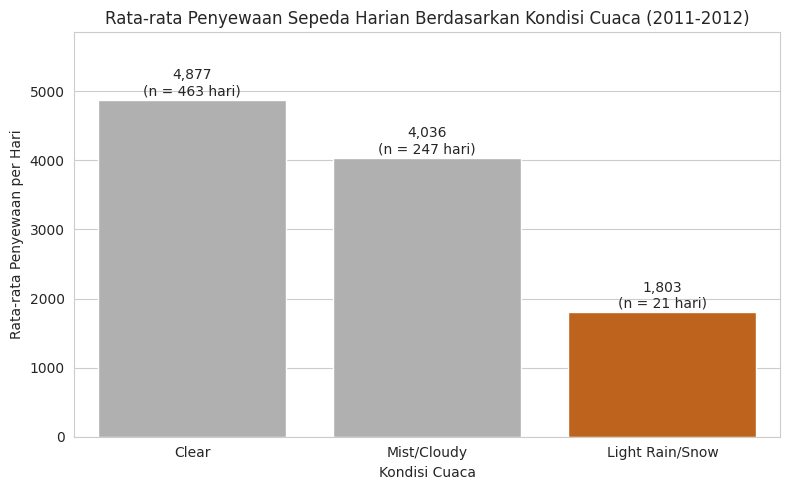

In [158]:
fig, ax = plt.subplots(figsize=(8, 5))

warna = ["#d95f02" if i == cuaca_df["rata_rata"].idxmin() else "#b0b0b0" for i in cuaca_df.index]
sns.barplot(x=cuaca_df.index, y=cuaca_df["rata_rata"], hue=cuaca_df.index,
            palette=warna, legend=False, ax=ax)

for i, (nilai, n) in enumerate(zip(cuaca_df["rata_rata"], cuaca_df["jumlah_hari"])):
    ax.text(i, nilai + 60, f"{nilai:,.0f}\n(n = {n} hari)", ha="center")

ax.set_ylim(0, cuaca_df["rata_rata"].max() * 1.2)
ax.set_title("Rata-rata Penyewaan Sepeda Harian Berdasarkan Kondisi Cuaca (2011-2012)")
ax.set_xlabel("Kondisi Cuaca")
ax.set_ylabel("Rata-rata Penyewaan per Hari")
plt.tight_layout()
plt.show()

### Pertanyaan 2:

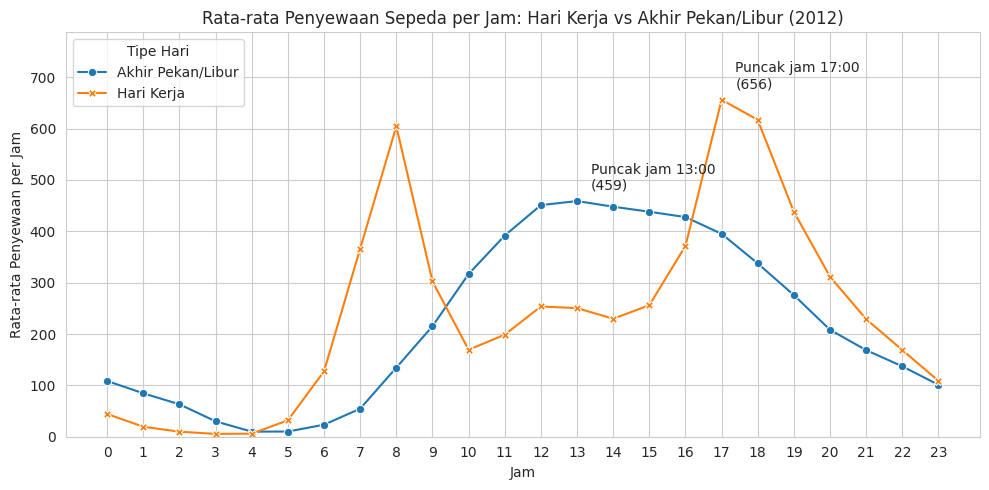

In [159]:

fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(data=pola_jam, dashes=False, markers=True, ax=ax)

for kolom in pola_jam.columns:
    jam = pola_jam[kolom].idxmax()
    ax.annotate(f"Puncak jam {jam}:00\n({pola_jam[kolom].max():.0f})",
                (jam, pola_jam[kolom].max()),
                textcoords="offset points", xytext=(10, 8))

ax.set_xticks(range(0, 24))
ax.set_title("Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan/Libur (2012)")
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata Penyewaan per Jam")
ax.legend(title="Tipe Hari")
ax.set_ylim(0, pola_jam.max().max() * 1.2)
plt.tight_layout()
plt.show()

**Insight:**
- Cuaca buruk menekan penyewaan secara jelas: Light Rain/Snow turun sekitar 63% dibanding cuaca cerah.
- Hari kerja punya dua puncak (pagi dan sore) khas jam berangkat dan pulang kerja, sedangkan akhir pekan berpola satu puncak di siang hari.

## Analisis Lanjutan (Opsional)

Pada bagian ini dilakukan dua teknik analisis lanjutan tanpa machine learning:
1. **Binning suhu** pada day_df: suhu (°C) dikelompokkan ke kategori Dingin, Sejuk, Hangat, dan Panas untuk melihat pengaruh suhu terhadap rata-rata penyewaan harian. Tujuannya memperkuat jawaban Pertanyaan 1 dengan faktor lain selain cuaca.
2. **Manual grouping jam** pada hour_df (2012): jam dikelompokkan menjadi Dini hari, Pagi, Siang, Sore, dan Malam berdasarkan pemahaman pola aktivitas harian. Tujuannya meringkas pola per jam pada Pertanyaan 2 menjadi periode waktu yang lebih mudah dibaca.

In [160]:
day_df["kategori_suhu"] = pd.cut(
    day_df["temp"],
    bins=[-float("inf"), 10, 20, 28, float("inf")],
    labels=["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-28°C)", "Panas (>28°C)"],
    right=False,
)

suhu_df = day_df.groupby("kategori_suhu", observed=True)["cnt"].agg(
    jumlah_hari="count", rata_rata="mean"
).round(1)
suhu_df

,jumlah_hari,rata_rata
kategori_suhu,,
Dingin (<10°C),60,1677.8
Sejuk (10-20°C),299,3692.3
Hangat (20-28°C),222,5580.8
Panas (>28°C),150,5660.6


In [161]:
hour_2012["kelompok_waktu"] = pd.cut(
    hour_2012["hr"],
    bins=[-1, 5, 10, 14, 18, 23],
    labels=["Dini hari (00-05)", "Pagi (06-10)", "Siang (11-14)", "Sore (15-18)", "Malam (19-23)"],
)

waktu_df = hour_2012.pivot_table(
    index="kelompok_waktu", columns="tipe_hari", values="cnt", aggfunc="mean", observed=True
).round(1)
waktu_df

tipe_hari,Akhir Pekan/Libur,Hari Kerja
kelompok_waktu,,
Dini hari (00-05),51.1,19.6
Pagi (06-10),148.9,314.1
Siang (11-14),437.4,233.1
Sore (15-18),399.6,475.2
Malam (19-23),178.1,251.2


**Insight:**
- Penyewaan naik seiring suhu: kategori Dingin paling rendah (sekitar 1.678/hari), sedangkan Hangat dan Panas hampir sama tinggi (sekitar 5.600/hari), jadi kenaikan melambat setelah suhu hangat.
- Hari kerja ramai pada Sore dan Pagi (jam berangkat dan pulang), sedangkan akhir pekan paling ramai pada Siang.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kondisi cuaca berpengaruh besar terhadap penyewaan harian selama 2011-2012. Cuaca cerah (Clear) memiliki rata-rata tertinggi, yaitu 4.876,8 sewa/hari. Mist/Cloudy turun 17,2% (4.035,9), dan Light Rain/Snow paling menurunkan penyewaan dengan penurunan 63,0% (1.803,3). Analisis lanjutan menunjukkan suhu juga berpengaruh: kategori Dingin (<10°C) hanya sekitar 1.678 sewa/hari, sedangkan Hangat dan Panas sekitar 5.600 sewa/hari. Catatan: kategori Light Rain/Snow hanya berisi 21 hari.
- **Conclusion pertanyaan 2:** Pada 2012, puncak penyewaan hari kerja terjadi pukul 17.00 (656,2 sewa/jam), dengan puncak kedua di pagi hari sekitar pukul 08.00, sehingga polanya mengikuti jam berangkat dan pulang kerja. Pada akhir pekan/libur, puncaknya pukul 13.00 (458,9 sewa/jam) dengan satu puncak di siang hari. Rata-rata penyewaan per jam hari kerja (241,2) lebih tinggi 20,5 dibanding akhir pekan/libur (220,7).

**Rekomendasi Action Item:**
- Siapkan stok sepeda dan jadwal perawatan dengan memperhitungkan prakiraan cuaca. Saat diperkirakan hujan atau salju ringan, kurangi alokasi sepeda yang disebar dan manfaatkan hari itu untuk perawatan armada.
- Pada hari kerja, pastikan sepeda tersedia dan terdistribusi merata di stasiun sekitar kantor dan permukiman sebelum jam 07.00-09.00 dan 16.00-19.00 (jam sibuk).
- Pada akhir pekan/libur, pindahkan fokus distribusi dan promo ke siang hari (sekitar 11.00-15.00), dan manfaatkan jam sepi hari kerja (siang hari) untuk rebalancing dan perawatan.
- Pertimbangkan promo khusus saat suhu dingin (<10°C) atau cuaca mendung, karena itu kondisi dengan permintaan paling rendah.

In [162]:
import os
os.makedirs("dashboard", exist_ok=True)
day_df.to_csv("dashboard/main_data.csv", index=False)
hour_df.to_csv("dashboard/hour_data.csv", index=False)